# v9b: lesion DURING normal continual training (GPU 1)
**Run All.** Runs next to `newtask_v9.ipynb` (GPU 0). Results: `analysis/v9/nextphase/` (separate folder, so the two never write the same file).

**Question:** when 10% of each layer's self neurons are switched off, does the model learn its NEXT phase (its next language, exactly as in normal continual training) worse than when the same number of look-alike task neurons are switched off?

- Start checkpoints (4): distant phase 30 (next = Hindi) and 40 (next = Chinese); related phase 10 (next = Gujarati) and 15 (next = Hindi).
- Training: 1,500 steps on the next language, normal script-masked loss. Score: chrF on 200 FLORES devtest sentences (steps 0, 500, 1500).
- Conditions (held for the whole training): nothing off / 10% self off / 10% look-alike task off / 10% random task off.
- 4 starts x 4 conditions x 3 seeds = 48 runs. Seed 0 of everything first.

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "1"          # second GPU (newtask_v9.ipynb uses GPU 0)
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def last_phase(run):
    phs = [int(os.path.basename(f)[1:4]) for f in FILES if f.startswith(f"{run}/ckpt/p")]
    phs += [int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{run}/ckpt/p*.pt")]
    return max(phs)

def run(langset, *cmd):
    env = {**os.environ, "CML_LANGSET": langset}
    p = subprocess.Popen([sys.executable, "-u", "newtask_v9.py", "--gpu", GPU, "--tasks", "next", "--out", "nextphase", *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

DIST, REL = "v4b_continual_s0", "v8_indic_continual_s0"
STARTS = [("distant", DIST, 30), ("distant", DIST, 40), ("indic", REL, 10), ("indic", REL, 15)]
for _, r, ph in STARTS:
    get(r, [ph])
print("start models:", [(r, ph) for _, r, ph in STARTS])

p030_ar.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p040_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

start models: [('v4b_continual_s0', 30), ('v4b_continual_s0', 40), ('v8_indic_continual_s0', 10), ('v8_indic_continual_s0', 15)]


In [2]:
need = [f"data/en-{l}/train.jsonl" for l in ["hi", "zh", "gu"]] + [f"data/flores/devtest.{l}.jsonl" for l in ["en", "hi", "zh", "gu"]]
need += [f"data/flores/dev.{l}.jsonl" for l in ["en", "hi", "zh", "ar", "gu", "pa"]] + [f"data/en-{l}/val.jsonl" for l in ["hi", "zh", "ar", "gu", "pa"]]
miss = [f for f in need if not os.path.exists(f)]
print("all there" if not miss else f"MISSING: {miss}  -> run your download snippet first, then re-run this cell")

all there


In [3]:
for s in ["0", "1", "2"]:
    for langset, r, ph in STARTS:
        run(langset, "--start", f"{'distant' if langset == 'distant' else 'related'}{ph}={r}:{ph}", "--seeds", s)
    subprocess.run([sys.executable, "newtask_v9.py", "--summarize", "--out", "nextphase"])

start model: distant30 = v4b_continual_s0 phase 30 (last trained on ar) | language set distant: hi, zh, ar
  enc0.mlp: 2560 working neurons, self = 1234 (48%), switching off 256
  enc1.mlp: 2560 working neurons, self = 1189 (46%), switching off 256
  enc2.mlp: 2560 working neurons, self = 1224 (48%), switching off 256
  enc3.mlp: 2560 working neurons, self = 1538 (60%), switching off 256
  dec0.mlp: 2560 working neurons, self = 1482 (58%), switching off 256
  dec1.mlp: 2560 working neurons, self = 1325 (52%), switching off 256
  dec2.mlp: 2560 working neurons, self = 1394 (54%), switching off 256
  dec3.mlp: 2560 working neurons, self = 2049 (80%), switching off 256
  self found in 5s
  'next' task for this start model = hi (phase 31 of the normal schedule)
runs to do in this call: 4 (1 tasks x 4 conditions x seeds [0]; already done are skipped)
  loaded next: 300,000 train examples
  distant30 | next       | none      | seed 0 | loss 5.595 -> 1.569 | score 9.4 -> score 48.3 | 143s | l

=== v9: learning a NEW task with part of the self switched off ===
one comparison = one start model x one seed x one task: self switched off vs look-alike task neurons switched off
learning slowness = average held-out loss over the learning curve (steps 50 ... end); lower = learned faster

AVERAGE OVER SEEDS (curve loss | final score; score = accuracy % or chrF for Indonesian)
                          curve_loss  final_score  seeds
task start     cond                                     
next distant30 lookalike       2.100       47.628      3
               none            2.051       47.713      3
               random          2.098       47.780      3
               self            2.110       47.974      3
     distant40 lookalike       2.589       23.436      3
               none            2.557       24.122      3
               random          2.582       23.570      3
               self            2.595       23.417      3
     related10 lookalike       2.384       42.339 

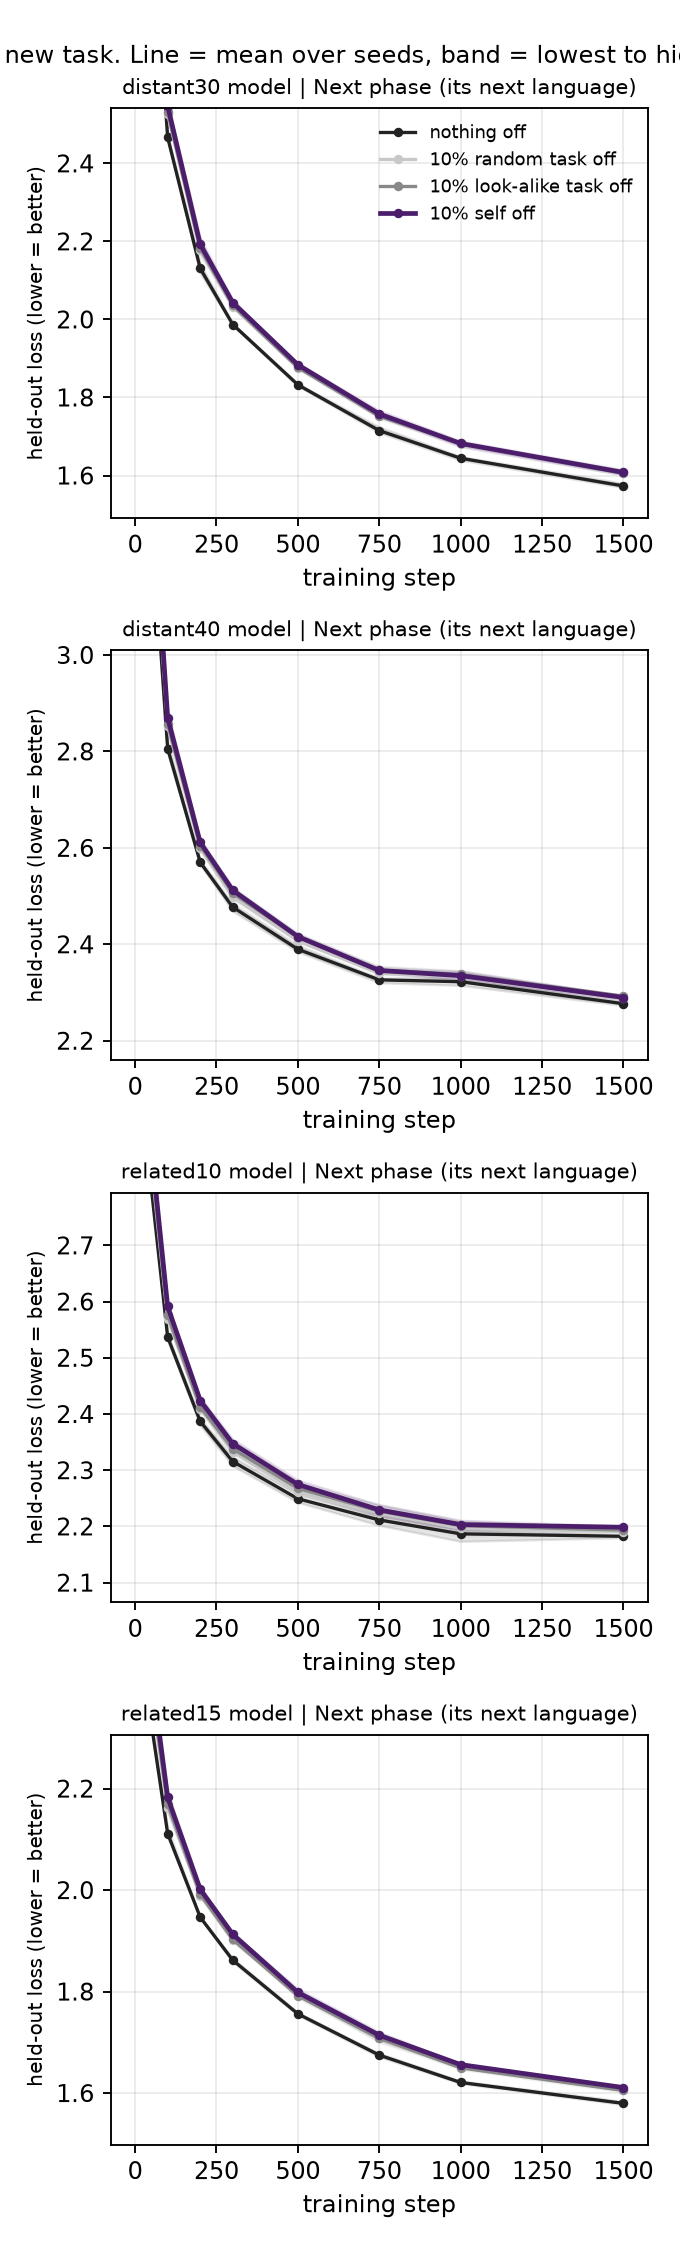

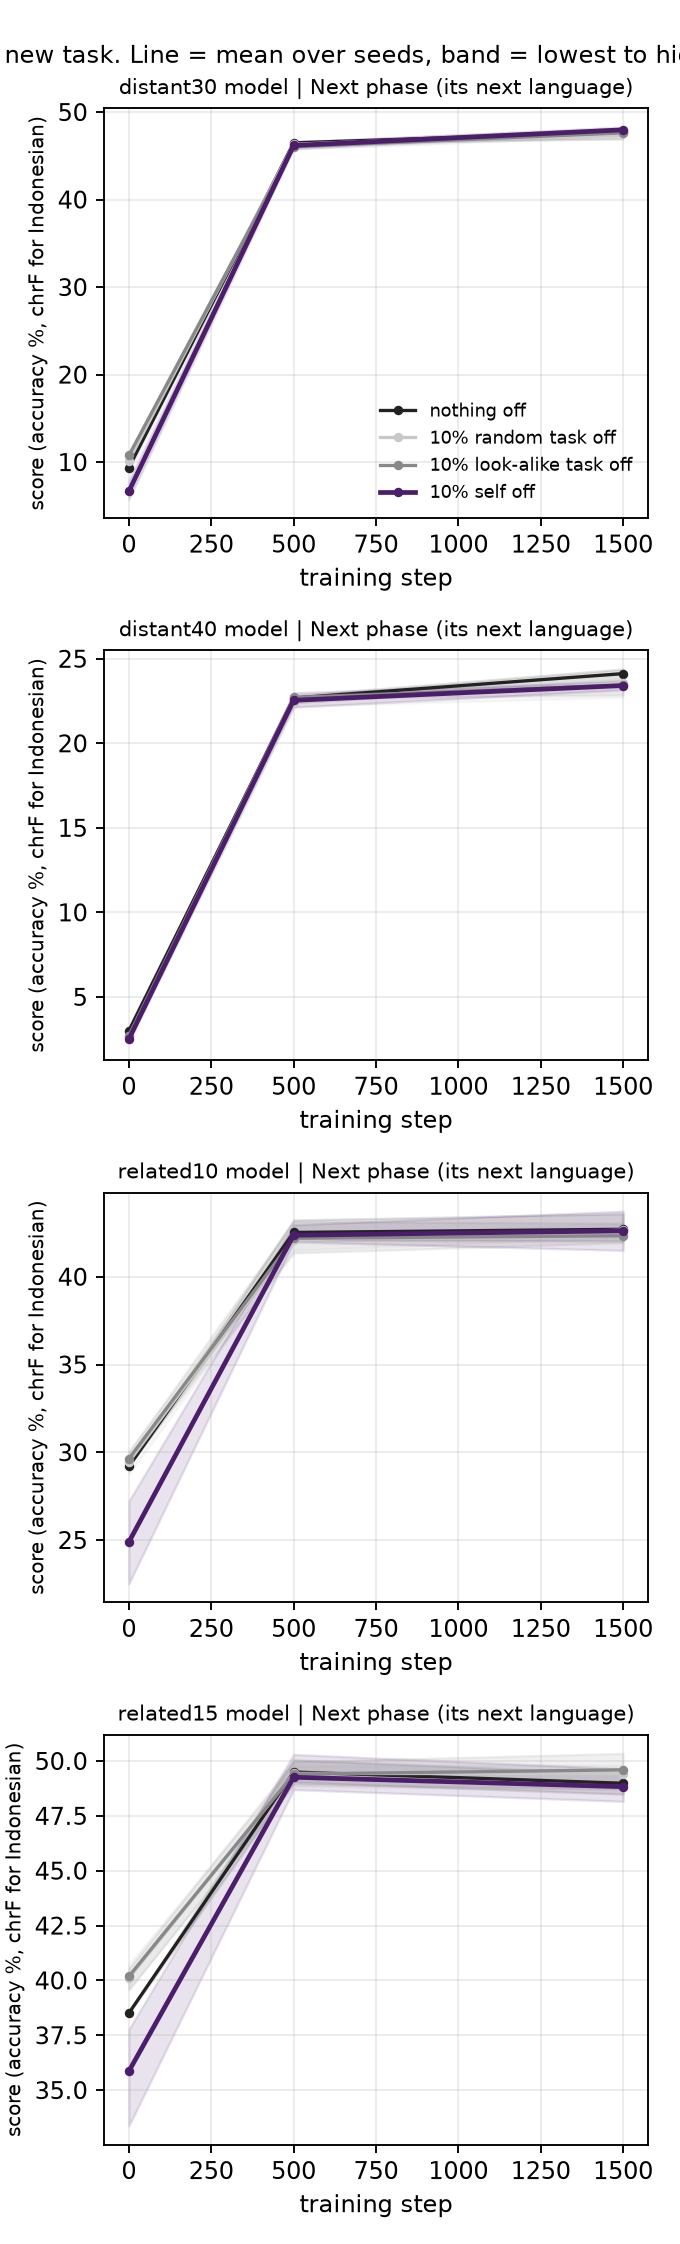

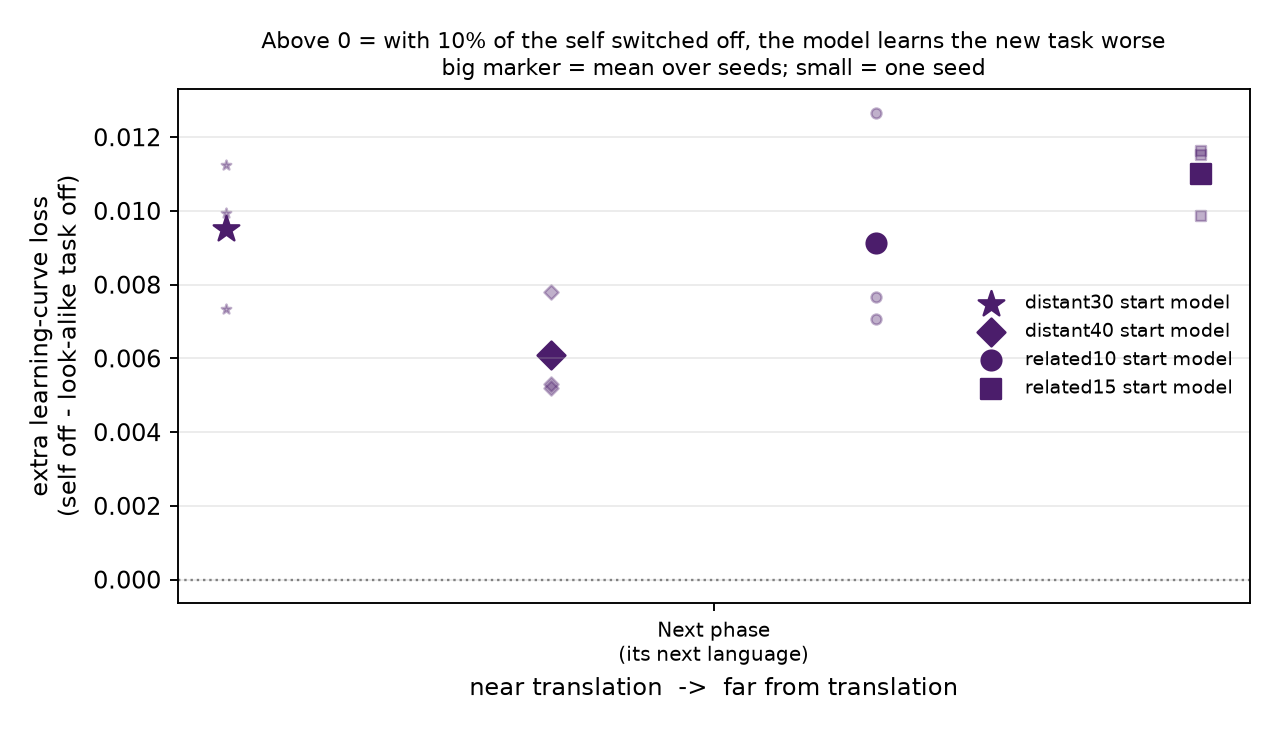

In [4]:
subprocess.run([sys.executable, "newtask_v9.py", "--summarize", "--out", "nextphase"])
for f in ["fig1_learning_curves_loss.png", "fig2_learning_curves_score.png", "fig3_near_to_far.png"]:
    display(Image(f"analysis/v9/nextphase/{f}"))